In [1]:
!pip install -q numpy==2.4.4 2>/dev/null
!pip install -q onnx==1.21.0 2>/dev/null
!pip install -q onnxruntime==1.24.4 2>/dev/null
!pip install -q onnx-tool==1.0.1 2>/dev/null

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 75.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.6/17.6 MB 69.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 73.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 1.7 MB/s eta 0:00:00


This starter notebook for the [2026 NeuroGolf Championship](https://www.kaggle.com/competitions/neurogolf-2026) is designed to help contestants verify the functional correctness of their networks.  It allows one to load example pairs for a task, visualize them, and test whether a candidate network produces expected results across all public competition benchmarks.

## Enter a task number (between 1 and 400):

In [2]:
task_num = 2  # Task 0 is just an illustrative example (and not eligible for points)

## Color legend

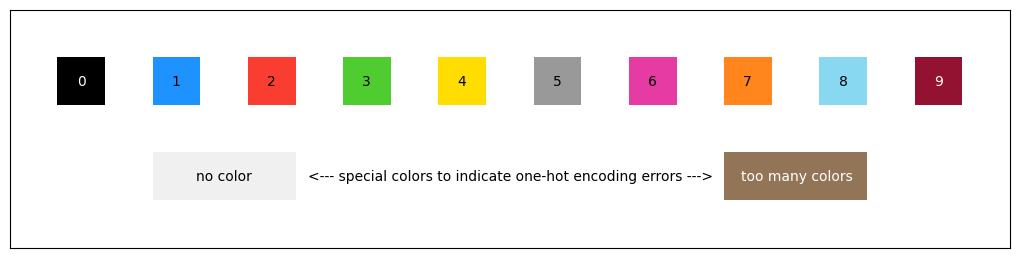

In [3]:
import sys
sys.path.append("/kaggle/input/competitions/neurogolf-2026/neurogolf_utils")
from neurogolf_utils import *
show_legend()

## Example <input, output> pairs

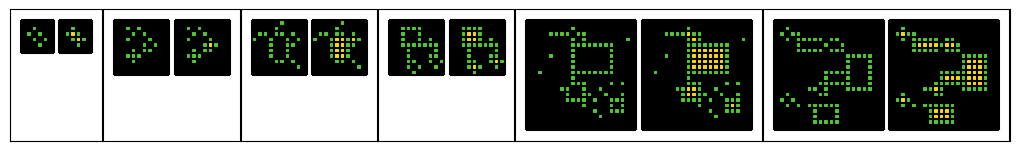

In [4]:
examples = load_examples(task_num)
show_examples(examples['train'] + examples['test'])

## Define your network to solve the task

The code below uses a utility we've provided to help you create [single-layer convolutional networks](https://en.wikipedia.org/wiki/Convolutional_layer).  It may be possible to solve other tasks in a similar way, but most will require more complicated architectures!

In [ ]:
def weight(channel_out, channel_in, kernel_coord):
  if kernel_coord == ( 0,  0) and channel_in == channel_out: return 1.0
  if kernel_coord == ( 0,  0) and channel_in != 5 and channel_out == 0: return -1.0
  if kernel_coord == (-1, -1) and channel_in != 5 and channel_out == 0: return 1.0
  if kernel_coord == (-1, -1) and channel_in != 5 and channel_out == 5: return -1.0
  return 0.0

network = single_layer_conv2d_network(weight, kernel_size=3)

In [5]:
import numpy as np
import onnx
from onnx import helper, TensorProto, numpy_helper

nodes = []
initializers = []

# ------------------------------------------------------------
# Utility helpers 
# ------------------------------------------------------------

def add_initializer(name, array):
    initializers.append(
        numpy_helper.from_array(array.astype(np.float32), name)
    )

def gather_channel(inp, channel, out):
    idx_name = f"idx_{channel}"

    if idx_name not in {i.name for i in initializers}:
        initializers.append(
            numpy_helper.from_array(
                np.array([channel], dtype=np.int64),
                idx_name
            )
        )

    nodes.append(
        helper.make_node(
            "Gather",
            [inp, idx_name],
            [out],
            axis=1
        )
    )


def mul(a, b, out):
    nodes.append(
        helper.make_node(
            "Mul",
            [a, b],
            [out]
        )
    )

border = np.zeros((1,1,30,30), dtype=np.float32)

border[:,:,0,:] = 1
border[:,:,-1,:] = 1
border[:,:,:,0] = 1
border[:,:,:,-1] = 1

add_initializer("border_const", border)
    
def conv(inp, weight_name, out, pads=(1,1,1,1)):
    nodes.append(
        helper.make_node(
            "Conv",
            inputs=[inp, weight_name],
            outputs=[out],
            pads=list(pads),
            strides=[1,1]
        )
    )

kernel = np.array(
    [[[
        [0,1,0],
        [1,0,1],
        [0,1,0]
    ]]],
    dtype=np.float32
)

add_initializer("cross_kernel", kernel)

def add(a, b, out):
    nodes.append(
        helper.make_node(
            "Add",
            [a, b],
            [out]
        )
    )

add_initializer(
    "zero_scalar",
    np.array(0, dtype=np.float32)
)

def greater(a, b, out):
    nodes.append(
        helper.make_node(
            "Greater",
            [a, b],
            [out]
        )
    )

def cast(inp, out):
    nodes.append(
        helper.make_node(
            "Cast",
            [inp],
            [out],
            to=TensorProto.FLOAT
        )
    )

def propagate(current, iteration):
    neighbor = f"neighbor_sum_{iteration}"
    expanded = f"expanded_sum_{iteration}"
    expanded_bool = f"expanded_bool_{iteration}"
    expanded_mask = f"expanded_mask_{iteration}"
    reach = f"reachable_{iteration}"
    conv(current, "cross_kernel", neighbor)
    add(neighbor, current, expanded)
    greater(expanded, "zero_scalar", expanded_bool)
    cast(expanded_bool, expanded_mask)
    mul(expanded_mask, "background_mask", reach)
    return reach

def sub(a, b, out):
    nodes.append(
        helper.make_node(
            "Sub",
            [a, b],
            [out]
        )
    )

def concat(inputs, out):
    nodes.append(
        helper.make_node(
            "Concat",
            inputs,
            [out],
            axis=1
        )
    )
# ------------------------------------------------------------
# Stage 1 
# ------------------------------------------------------------

gather_channel("input", 0, "background_mask")

gather_channel("input", 3, "color3_mask")

mul(
    "background_mask",
    "border_const",
    "border_seed"
)

reach = "border_seed"

for i in range(60):
    reach = propagate(reach, i)


sub(
    "background_mask",
    reach,
    "holes"
)

sub(
    "background_mask",
    "holes",
    "background_new"
)

gather_channel("input", 4, "color4_mask")
add(
    "color4_mask",
    "holes",
    "color4_new"
)

gather_channel("input", 1, "channel1")
gather_channel("input", 2, "channel2")
gather_channel("input", 5, "channel5")
gather_channel("input", 6, "channel6")
gather_channel("input", 7, "channel7")
gather_channel("input", 8, "channel8")
gather_channel("input", 9, "channel9")

concat(
    [
        "background_new",
        "channel1",
        "channel2",
        "color3_mask",
        "color4_new",
        "channel5",
        "channel6",
        "channel7",
        "channel8",
        "channel9"
    ],
    "output"
)

outputs = [
    helper.make_tensor_value_info(
        "output",
        TensorProto.FLOAT,
        [1,10,30,30]
    )
]
input_info = helper.make_tensor_value_info(
    "input",
    TensorProto.FLOAT,
    [1,10,30,30]
)

graph = helper.make_graph(
    nodes,
    "task002",
    [input_info],
    outputs,
    initializer=initializers
)

def make_model(graph):
    model = helper.make_model(
        graph,
        producer_name="Neurogolf",
        opset_imports=[helper.make_opsetid("", 21)]
    )

    # Use an IR version compatible with ONNX Runtime
    model.ir_version = 10
    return model

model = make_model(graph)

onnx.checker.check_model(model)
onnx.save(model, "task002.onnx")

In [27]:
network = task001_network()

onnx.save(network, "task001.onnx")

session = onnxruntime.InferenceSession("task001.onnx")

bench = convert_to_numpy(examples["train"][0])

inp = bench["input"]
expected = bench["output"]

output, patch, kron6, kron6_t, small = session.run(
    None,
    {"input": inp}
)


## Verify your network

In [46]:
import onnxruntime as ort
import numpy

examples = load_examples(2)["train"]

sess = ort.InferenceSession("task002.onnx")

bench = convert_to_numpy(load_examples(2)["train"][3])

background30 = bench["input"][0,0][:10,:10]

grid = np.array(load_examples(2)["train"][3]["input"])
background10 = (grid == 0).astype(np.float32)

print("Different pixels:",
      np.sum(background30 != background10))

print(np.argwhere(background30 != background10))

reach30 = bfs_fill(background30)
reach10 = bfs_fill(background10)

print("Reach difference:",
      np.sum(reach30 != reach10))

print(np.argwhere(reach30 != reach10))
# import matplotlib.pyplot as plt

# names = [
#     "border_seed",
#     "neighbor_sum_0",
#     "expanded_sum_0",
#     "expanded_mask_0",
#     "reachable_0"
# ]

# tensors = [
#     border_seed,
#     neighbor_sum_0,
#     expanded_sum_0,
#     expanded_mask_0,
#     reachable_0
# ]

# fig, ax = plt.subplots(1, 5, figsize=(20,4))

# for i, (name, t) in enumerate(zip(names, tensors)):
#     ax[i].imshow(t[0,0,:10,:10], cmap="gray")
#     ax[i].set_title(name)
#     ax[i].axis("off")

# plt.tight_layout()
# plt.show()

Different pixels: 0
[]
Reach difference: 0
[]


In [42]:
from collections import deque
import numpy as np
import matplotlib.pyplot as plt

examples = load_examples(2)["train"]

dirs = [(1,0),(-1,0),(0,1),(0,-1)]

for ex_id, ex in enumerate(examples):

    inp = np.array(ex["input"])
    out = np.array(ex["output"])

    print("="*70)
    print("Example", ex_id)

    background = (inp == 0)

    H, W = background.shape
    visited = np.zeros_like(background, dtype=bool)

    components = []

    for r in range(H):
        for c in range(W):

            if not background[r,c] or visited[r,c]:
                continue

            q = deque([(r,c)])
            visited[r,c]=True

            comp=[]

            touches_border=False

            while q:

                x,y=q.popleft()

                comp.append((x,y))

                if x==0 or y==0 or x==H-1 or y==W-1:
                    touches_border=True

                for dx,dy in dirs:

                    nx=x+dx
                    ny=y+dy

                    if 0<=nx<H and 0<=ny<W:

                        if background[nx,ny] and not visited[nx,ny]:

                            visited[nx,ny]=True
                            q.append((nx,ny))

            rows=[p[0] for p in comp]
            cols=[p[1] for p in comp]

            bbox=(min(rows),max(rows),min(cols),max(cols))

            becomes4=0

            for x,y in comp:
                if out[x,y]==4:
                    becomes4+=1

            components.append({
                "size":len(comp),
                "border":touches_border,
                "bbox":bbox,
                "becomes4":becomes4,
                "coords":comp
            })

    for i, c in enumerate(components):
        if not c["border"]:
            print()
            print("Component", i)
            print("size =", c["size"])
            print(c["coords"])

    # fig,ax=plt.subplots(1,2,figsize=(8,4))

    # ax[0].imshow(inp)
    # ax[0].set_title("Input")

    # ax[1].imshow(out)
    # ax[1].set_title("Output")

    # plt.show()

Example 0

Component 1
size = 1
[(2, 2)]

Component 2
size = 1
[(3, 3)]
Example 1

Component 1
size = 1
[(4, 6)]
Example 2

Component 2
size = 8
[(3, 4), (4, 4), (3, 5), (5, 4), (4, 5), (6, 4), (5, 5), (6, 5)]

Component 3
size = 1
[(3, 7)]
Example 3

Component 1
size = 4
[(2, 3), (3, 3), (2, 4), (3, 4)]

Component 3
size = 1
[(7, 8)]

Component 4
size = 1
[(8, 4)]
Example 4

Component 1
size = 1
[(2, 8)]

Component 2
size = 1
[(3, 9)]

Component 3
size = 24
[(5, 9), (6, 9), (5, 10), (7, 9), (6, 10), (5, 11), (8, 9), (7, 10), (6, 11), (5, 12), (8, 10), (7, 11), (6, 12), (5, 13), (8, 11), (7, 12), (6, 13), (5, 14), (8, 12), (7, 13), (6, 14), (8, 13), (7, 14), (8, 14)]

Component 4
size = 4
[(12, 8), (13, 8), (12, 9), (13, 9)]

Component 5
size = 1
[(15, 16)]


In [30]:
import numpy as np
import matplotlib.pyplot as plt

kernel = np.array([
    [0,1,0],
    [1,0,1],
    [0,1,0]
], dtype=np.float32)

bench = convert_to_numpy(load_examples(2)["train"][3])

background = bench["input"][0,0]

border = np.zeros_like(background)

border[0,:] = 1
border[-1,:] = 1
border[:,0] = 1
border[:,-1] = 1

border_seed = background * border

def conv4(mask):

    out = np.zeros_like(mask)

    out[1:,:] += mask[:-1,:]      # from above
    out[:-1,:] += mask[1:,:]      # from below
    out[:,1:] += mask[:,:-1]      # from left
    out[:,:-1] += mask[:,1:]      # from right

    return out
    
def propagate(mask, background):

    neighbor = conv4(mask)

    expanded = (neighbor + mask) > 0

    return expanded.astype(np.float32) * background

reachable = border_seed.copy()

history = [reachable.copy()]

for i in range(6):
    reachable = propagate(reachable, background)
    history.append(reachable.copy())

[0 1 3]


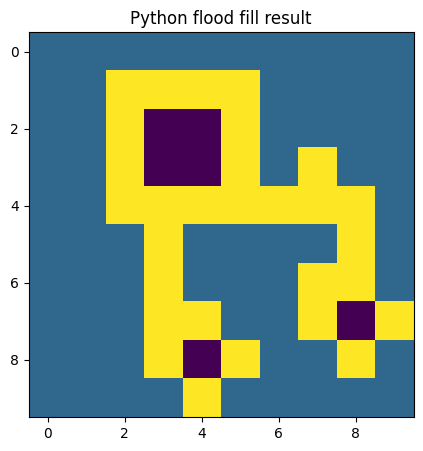

In [17]:
#===== TASK002 DEBUG =====
import numpy as np

def python_flood_fill(grid):
    """
    Reference implementation of the winning solution.
    Returns the intermediate y array AFTER flood fill.
    """

    y = np.where(grid==0,0,3)

    def e(r,c):
        try:
            if y[r][c] < 1:
                # if r < 0 or c < 0:
                #     print(f"Visiting ({r}, {c})")
                y[r][c]=1
                e(r+1,c)
                e(r-1,c)
                e(r,c+1)
                e(r,c-1)
        except:
            pass

    for i in range(len(y)):
        e(i,0)
        e(i,-1)
        e(0,i)
        e(-1,i)

    return y

example = load_examples(2)["train"][3]

grid = np.array(example["input"])

y = python_flood_fill(grid)

print(np.unique(y))

import matplotlib.pyplot as plt

plt.figure(figsize=(5,5))
plt.imshow(y,cmap="viridis")
plt.title("Python flood fill result")
plt.show()

In [44]:
from collections import deque

def bfs_fill(background):

    H, W = background.shape

    reach = np.zeros_like(background, dtype=np.float32)

    q = deque()

    for r in range(H):
        for c in [0, W-1]:
            if background[r,c]:
                reach[r,c] = 1
                q.append((r,c))

    for c in range(W):
        for r in [0, H-1]:
            if background[r,c] and reach[r,c] == 0:
                reach[r,c] = 1
                q.append((r,c))

    while q:

        r,c = q.popleft()

        for dr,dc in [(1,0),(-1,0),(0,1),(0,-1)]:

            nr = r + dr
            nc = c + dc

            if 0 <= nr < H and 0 <= nc < W:

                if background[nr,nc] and reach[nr,nc] == 0:

                    reach[nr,nc] = 1
                    q.append((nr,nc))

    return reach

In [47]:
verify_network(model, task_num, examples)


TypeError: list indices must be integers or slices, not str

In [20]:
# print(reachable.shape)
# reachable = reachable[:10, :10]
# python_reachable = (y == 1).astype(np.float32)
# diff = python_reachable != reachable

# print("Different pixels:", np.sum(diff))
# print(np.argwhere(diff))

# plt.figure(figsize=(5,5))
# plt.imshow(diff,cmap="gray")
# plt.title("Difference")
# plt.show()

python_reach = (python_flood_fill(grid) == 1).astype(np.float32)

bfs_reach = bfs_fill(grid == 0)

print("Different pixels:", np.sum(python_reach != bfs_reach))

print(np.sum(python_reach != bfs_reach))


Different pixels: 0
0
